# 01 · Explore the BTS flight data (one month: July 2025)

**Goal (CLAUDE.md, Phase 1, step 1.2):** understand the flight table before building anything on it.
We use **one month only** (July 2025): it is big enough to see real patterns and small enough to run fast.

Rules used in this notebook:
- The raw ZIP is read directly from `data_dir` (outside the repo). **Nothing is written to disk.**
- Time columns are read **as text** (`"0659"` must not become `659`).
- The delay-cause columns are only **looked at** here. They are known after the flight, so they are **never model inputs**.

## 0. Setup

**What:** import the libraries and read `config.yaml` to find the data folder and the 10 hubs.
**Why:** paths are never written by hand in the code, so the same notebook works on another PC by changing only `config.yaml`.

In [1]:
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

# The notebook runs from notebooks/, config.yaml sits one folder up (the repo root).
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load((REPO / "config.yaml").read_text(encoding="utf-8"))

HUBS = cfg["hubs"]
BTS_ZIP = Path(cfg["data_dir"]) / "raw" / "bts" / "bts_2025_07.zip"
print("hubs:", HUBS)
print("file:", BTS_ZIP, "| exists:", BTS_ZIP.exists())

hubs: ['ATL', 'ORD', 'DFW', 'DEN', 'LAX', 'JFK', 'CLT', 'LAS', 'PHX', 'SEA']
file: C:\data\flight-delay\raw\bts\bts_2025_07.zip | exists: True


**What:** read the month. The ZIP holds a CSV **and** a `readme.html`, so we open the `.csv` member by name.
We read only the columns we need (110 exist), and the 4 clock-time columns as text.

**Why:** fewer columns = less memory and faster. Text times keep the leading zero (`"0659"`), which we need later to build real timestamps.

In [2]:
TIME_COLS = ["CRSDepTime", "DepTime", "CRSArrTime", "ArrTime"]   # HHMM local clock times
COLS = [
    "FlightDate", "Reporting_Airline", "Flight_Number_Reporting_Airline", "Tail_Number",
    "Origin", "Dest", "OriginAirportID", "DestAirportID",
    *TIME_COLS, "CRSElapsedTime",
    "DepDelay", "DepDel15", "ArrDelay", "ArrDel15", "Cancelled", "Diverted",
    "CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay",
]


def read_bts_month(zip_path: Path, columns: list[str]) -> pd.DataFrame:
    """Read the CSV inside one BTS monthly ZIP (not the readme), time columns as strings."""
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = next(n for n in zf.namelist() if n.lower().endswith(".csv"))
        with zf.open(csv_name) as f:
            return pd.read_csv(f, usecols=columns, dtype={c: str for c in TIME_COLS},
                               low_memory=False)


df = read_bts_month(BTS_ZIP, COLS)
df["FlightDate"] = pd.to_datetime(df["FlightDate"], format="%Y-%m-%d")   # explicit format
print("shape:", df.shape)
print(f"memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
df.head()

shape: (631428, 24)
memory: 140 MB


,FlightDate,Reporting_Airline,Tail_Number,Flight_Number_Reporting_Airline,OriginAirportID,Origin,DestAirportID,Dest,CRSDepTime,DepTime,...,ArrDelay,ArrDel15,Cancelled,Diverted,CRSElapsedTime,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2025-07-23,AA,N450AN,969,13303,MIA,11057,CLT,0832,0829,...,-5.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN
1,2025-07-24,AA,N431AN,969,13303,MIA,11057,CLT,0832,0957,...,74.0,1.0,0.0,0.0,130.0,0.0,0.0,0.0,0.0,74.0
2,2025-07-25,AA,N444UW,969,13303,MIA,11057,CLT,0832,0828,...,-18.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN
3,2025-07-26,AA,N462AA,969,13303,MIA,11057,CLT,0832,0827,...,10.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN
4,2025-07-27,AA,N458AL,969,13303,MIA,11057,CLT,0832,0836,...,-13.0,0.0,0.0,0.0,130.0,NaN,NaN,NaN,NaN,NaN


**What:** compare the number of rows with the count found during the download check (631,428).
**Why:** a different number would mean the file was read wrongly (wrong member, cut file, bad parsing).

In [3]:
EXPECTED_ROWS = 631_428
print(f"rows read: {len(df):,} | expected: {EXPECTED_ROWS:,} | match: {len(df) == EXPECTED_ROWS}")
print("dates:", df["FlightDate"].min().date(), "->", df["FlightDate"].max().date())
print("time column types:", df[TIME_COLS].dtypes.unique())

rows read: 631,428 | expected: 631,428 | match: True
dates: 2025-07-01 -> 2025-07-31
time column types: [<StringDtype(na_value=nan)>]


**Question:** Does the row count match 631,428? If one day it does not, what are 2 possible reasons?

**My answer:**
yes it matchest the count
 if  one day it does not it might be because there are no flights in that day they are all canveled or there is a carrier or weather delay 


## 1. Counts: flights, airlines, airports, hubs

**What:** how many flights, airlines and departure airports, and how many flights leave from our 10 hubs.
**Why:** our scope is "flights departing from the 10 hubs". We need to know how much of the US traffic that keeps.

In [5]:
from_hub = df["Origin"].isin(HUBS)
summary = pd.Series({
    "flights": len(df),
    "airlines (Reporting_Airline)": df["Reporting_Airline"].nunique(),
    "origin airports": df["Origin"].nunique(),
    "flights from the 10 hubs": int(from_hub.sum()),
    "share from the 10 hubs (%)": round(100 * from_hub.mean(), 1),
})
summary.to_frame("value")

,value
flights,631428.0
airlines (Reporting_Airline),14.0
origin airports,345.0
flights from the 10 hubs,208298.0
share from the 10 hubs (%),33.0


**What:** flights per hub, as a bar chart.
**Why:** hubs are not equal: a big hub gives the model many more examples than a small one.

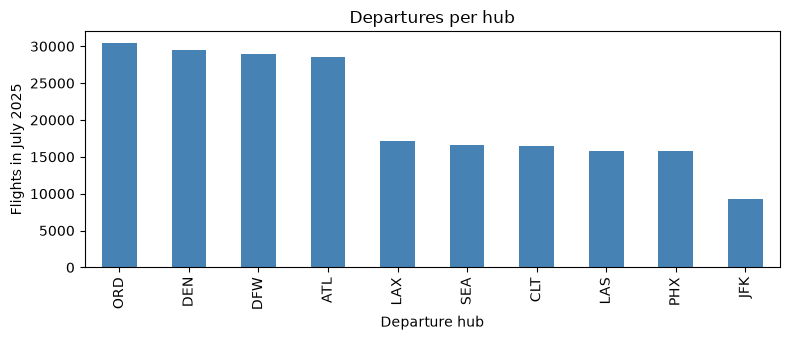

In [6]:
per_hub = df.loc[from_hub, "Origin"].value_counts()
ax = per_hub.plot.bar(figsize=(8, 3.5), color="steelblue")
ax.set_xlabel("Departure hub")
ax.set_ylabel("Flights in July 2025")
ax.set_title("Departures per hub")
plt.tight_layout()
plt.show()

**Question:** What share of all US domestic flights leaves from our 10 hubs? Is one month of it enough data to train on, or why do we need 2024–2025?

**My answer:**
the share it rperenstnst out of usa is 33% i know we took airports in  different big states only where there is be the most percentage of flights 33%  for only 10 hubs compared to the rest in 67% in the other 335 , and we need two years worth of data since it the trained model will be trained on various season at least each season saw it twice more data can lead to more precise results 

## 2. Is there a unique key for a flight?

**What:** check that (date, airline, flight number, origin, scheduled departure) identifies exactly one row.
**Why:** every later join (weather, radar, previous leg) attaches data **to one flight**. If the key is not unique,
a join can silently duplicate rows. The Gold table test `test_no_duplicate_flights` depends on this.

In [9]:
KEY = ["FlightDate", "Reporting_Airline", "Flight_Number_Reporting_Airline", "Origin", "CRSDepTime"]

dup = df.duplicated(KEY, keep=False)        # keep=False marks EVERY copy, not only the 2nd
print(f"rows sharing a key: {dup.sum():,} ({100 * dup.mean():.3f} %)")
df.loc[dup, KEY + ["Dest", "Tail_Number", "Cancelled"]].sort_values(KEY).head(10)

rows sharing a key: 0 (0.000 %)


,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,CRSDepTime,Dest,Tail_Number,Cancelled


**Question:** Is the key unique? If not, what do the duplicates look like, and what would you add to the key (or remove) to fix it?

**my answer** :yes the key is unique since no rows share the same key , i i found a duplicate i drop them and i leave just one not duplicated among them (the drop happens if the rows are identical)

## 3. Cancelled, diverted and missing tail numbers

**What:** the share of flights that were cancelled, diverted, or have no tail number.
**Why:**
- cancelled flights have **no delay**: they can never be a delay label;
- diverted flights end at another airport: they break the aircraft's chain;
- without a tail number we cannot build the rotation (previous/next leg) at all.

In [10]:
tail = df["Tail_Number"].astype("string").str.strip()
shares = pd.Series({
    "cancelled": df["Cancelled"].eq(1).mean(),
    "diverted": df["Diverted"].eq(1).mean(),
    "missing tail number": (tail.isna() | tail.eq("")).mean(),
}) * 100
shares.round(2).to_frame("% of flights")

,% of flights
cancelled,2.45
diverted,0.50
missing tail number,0.27


**What:** are missing tail numbers mostly on cancelled flights?
**Why:** if the aircraft never flew, a missing tail is expected; on flown flights it is a real gap in the chain.

In [11]:
pd.crosstab(tail.isna() | tail.eq(""), df["Cancelled"].eq(1),
            rownames=["tail missing"], colnames=["cancelled"])

cancelled,False,True
tail missing,,
False,615955,13779
True,0,1694


**Question:** Why must cancelled flights never be used as a delay label? What happens to the rotation of a flight with no tail number?

**My answer:** canceled flights if used they will wreck the chain of delays and they will be like noise misinformation and degrade the quality of prediction . and regarding the rotation of flights with no tail number must be dropped for the data since it breaks the chain. also we conclude from the table that all canceled flights have no tail , so we drop canceled flighs with tail missing and also cnaceled with tail .

## 4. How are departure delays distributed?

**What:** histogram of `DepDelay` (minutes) for flights that were not cancelled. Two versions:
1. clipped to −30…180 min, normal scale: shows the bulk of flights;
2. full range, **log scale** on the counts: shows the rare, very long delays (the "long right tail").

**Why:** the shape tells us how to train. A long tail means a few huge delays can dominate the error → log transform or capping for regression (CLAUDE.md §11).
Negative values = the flight left **early**.

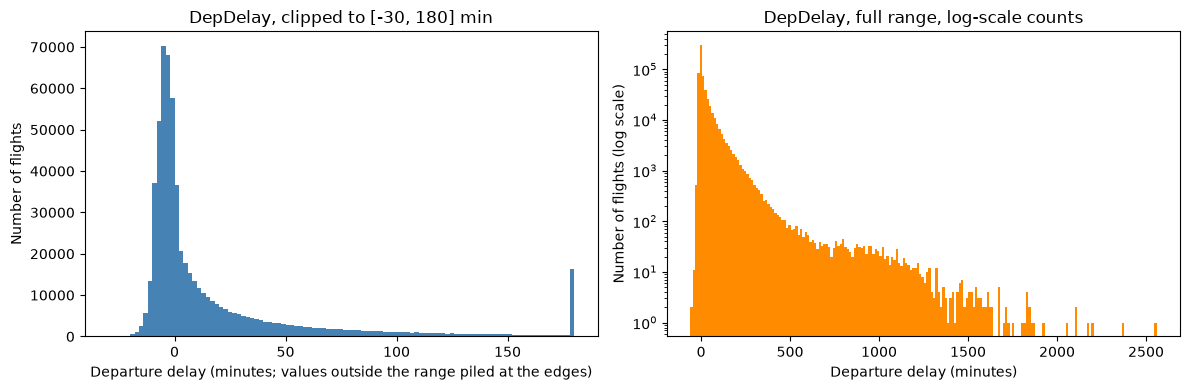

In [12]:
flown = df[df["Cancelled"].eq(0)]
dep = flown["DepDelay"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(dep.clip(-30, 180), bins=105, color="steelblue")
axes[0].set_title("DepDelay, clipped to [-30, 180] min")
axes[0].set_xlabel("Departure delay (minutes; values outside the range piled at the edges)")
axes[0].set_ylabel("Number of flights")

axes[1].hist(dep, bins=200, color="darkorange", log=True)
axes[1].set_title("DepDelay, full range, log-scale counts")
axes[1].set_xlabel("Departure delay (minutes)")
axes[1].set_ylabel("Number of flights (log scale)")
plt.tight_layout()
plt.show()

**What:** percentiles, mean vs. median, and the share of flights delayed ≥ 15 min.
**Why:** the 15-min threshold is our classification target; its share tells us how **imbalanced** the classes are.

In [13]:
pct = dep.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999])
pct.index = [f"p{q * 100:g}" for q in pct.index]
print(f"mean = {dep.mean():.1f} min | median = {dep.median():.1f} min | max = {dep.max():.0f} min")
print(f"share delayed >= 15 min: {100 * (dep >= 15).mean():.1f} %")
pct.round(1).to_frame("DepDelay (min)").T

mean = 21.4 min | median = -1.0 min | max = 2560 min
share delayed >= 15 min: 28.6 %


,p1,p5,p25,p50,p75,p90,p95,p99,p99.9
DepDelay (min),-14.0,-10.0,-5.0,-1.0,20.0,70.0,122.0,281.0,932.0


**What:** check that the BTS flag `DepDel15` really equals `DepDelay >= 15` on flown flights.
**Why:** we will use one of them as the label; they must agree. Disagreements would be a data error to report.

In [14]:
both = flown.dropna(subset=["DepDelay", "DepDel15"])
mismatch = both["DepDel15"].ne((both["DepDelay"] >= 15).astype(float))
print(f"flown flights checked: {len(both):,} | mismatches: {mismatch.sum():,}")
print(f"flown flights with no DepDelay: {flown['DepDelay'].isna().sum():,}")
both.loc[mismatch, ["FlightDate", "Reporting_Airline", "Origin", "DepDelay", "DepDel15"]].head()

flown flights checked: 615,955 | mismatches: 0
flown flights with no DepDelay: 0


,FlightDate,Reporting_Airline,Origin,DepDelay,DepDel15


**Question:** Why is the median much lower than the mean? What does the long tail mean for the regression target and for MAE? How imbalanced is the ≥ 15 min class?

**My answer:** regarding the median is lower than the mean because the mean is the sum of values devided by axis x however the median represents the value that sits exacltly in the middle lets say most commun . the long tail means data is right skewed and for the regression it means we need to balance the data and for mae it means "i dont know " and the >=15 min class is less than the oppopsite thats why we need to balance it 

## 5. Where and when are delays bigger?

**What:** average departure delay and share ≥ 15 min by **scheduled local hour** of departure.
**Why:** the CLAUDE.md check question "why do delays grow later in the day?". Local hour is right here: it is the airport's own day.
`CRSDepTime = "2400"` means midnight; we count it as hour 0.

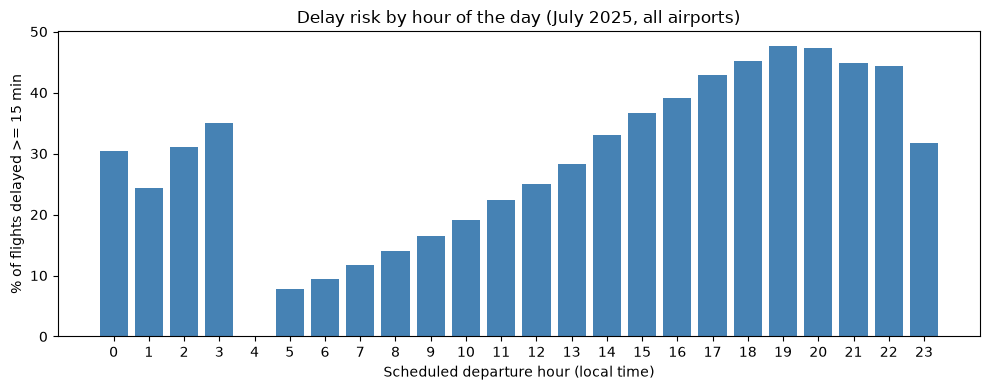

dep_hour,0,1,2,3,5,6,7,8,9,10,...,14,15,16,17,18,19,20,21,22,23
flights,1342.0,303.00,148.00,60.00,19235.00,43276.00,45347.00,41161.00,34807.00,37490.00,...,35174.00,34634.00,34114.00,37404.00,35286.00,33911.00,28795.00,21879.00,15811.00,6237.00
mean_delay,18.0,23.06,18.24,46.90,4.64,6.19,6.08,7.84,8.59,10.60,...,25.69,28.40,31.66,38.07,38.88,41.16,38.51,35.55,34.35,23.09
share_15,0.3,0.24,0.31,0.35,0.08,0.09,0.12,0.14,0.16,0.19,...,0.33,0.37,0.39,0.43,0.45,0.48,0.47,0.45,0.44,0.32


In [15]:
def scheduled_hour(hhmm: pd.Series) -> pd.Series:
    """Local scheduled hour (0-23) from an 'HHMM' text column; '2400' counts as hour 0."""
    return hhmm.str.zfill(4).str[:2].astype(int) % 24


flown = flown.assign(dep_hour=scheduled_hour(flown["CRSDepTime"]),
                     late15=flown["DepDelay"] >= 15)
by_hour = flown.groupby("dep_hour").agg(flights=("DepDelay", "size"),
                                        mean_delay=("DepDelay", "mean"),
                                        share_15=("late15", "mean"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_hour.index, 100 * by_hour["share_15"], color="steelblue")
ax.set_xlabel("Scheduled departure hour (local time)")
ax.set_ylabel("% of flights delayed >= 15 min")
ax.set_title("Delay risk by hour of the day (July 2025, all airports)")
ax.set_xticks(range(24))
plt.tight_layout()
plt.show()
by_hour.round(2).T

**What:** the same two numbers for each of our 10 hubs (departures only).
**Why:** if hubs behave very differently, the airport is a useful input, and the error analysis (Phase 4) must look per hub.

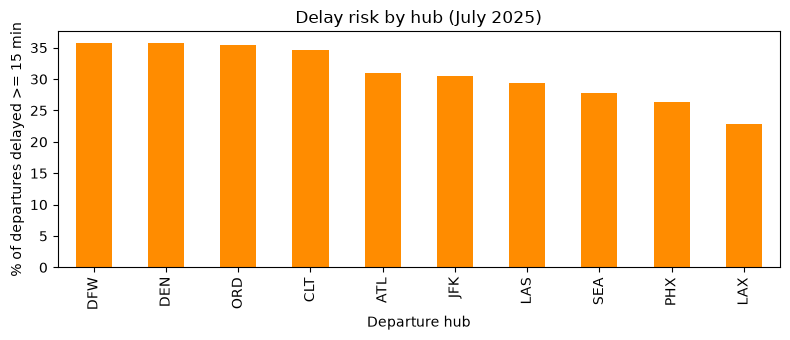

,flights,mean_delay,share_15
Origin,,,
DFW,28061,25.74,0.36
DEN,28996,27.90,0.36
ORD,29711,28.74,0.35
CLT,16067,26.15,0.35
ATL,28098,21.39,0.31
JFK,8685,26.44,0.31
LAS,15555,17.96,0.29
SEA,16349,15.42,0.28
PHX,15576,16.70,0.26


In [17]:
hub_flown = flown[flown["Origin"].isin(HUBS)]
by_hub = (hub_flown.groupby("Origin")
          .agg(flights=("DepDelay", "size"), mean_delay=("DepDelay", "mean"),
               share_15=("late15", "mean"))
          .sort_values("share_15", ascending=False))

ax = (100 * by_hub["share_15"]).plot.bar(figsize=(8, 3.5), color="darkorange")
ax.set_xlabel("Departure hub")
ax.set_ylabel("% of departures delayed >= 15 min")
ax.set_title("Delay risk by hub (July 2025)")
plt.tight_layout()
plt.show()
by_hub.round(2)

**What:** the same for each airline.
**Why:** airlines have different schedules, buffers and networks: the airline is likely a strong input.

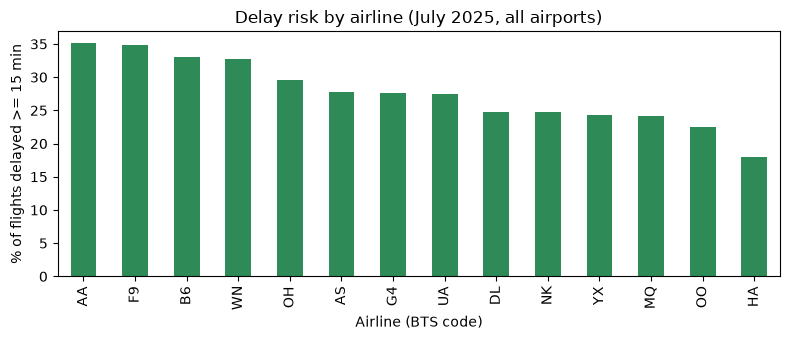

,flights,mean_delay,share_15
Reporting_Airline,,,
AA,84893,31.35,0.35
F9,15940,29.59,0.35
B6,19647,28.87,0.33
WN,124072,20.53,0.33
OH,19698,29.80,0.30
AS,23107,13.73,0.28
G4,13916,21.56,0.28
UA,68570,23.54,0.28
DL,92746,17.28,0.25


In [18]:
by_airline = (flown.groupby("Reporting_Airline")
              .agg(flights=("DepDelay", "size"), mean_delay=("DepDelay", "mean"),
                   share_15=("late15", "mean"))
              .sort_values("share_15", ascending=False))

ax = (100 * by_airline["share_15"]).plot.bar(figsize=(8, 3.5), color="seagreen")
ax.set_xlabel("Airline (BTS code)")
ax.set_ylabel("% of flights delayed >= 15 min")
ax.set_title("Delay risk by airline (July 2025, all airports)")
plt.tight_layout()
plt.show()
by_airline.round(2)

**Question:** Why do delays grow later in the day? Which hub and which airline stand out, and is one month enough to trust that ranking?

**My answer:** i think the delays grow at the end of the day since there is accumulation through the day of small delays or something . the hub that stand out is dfw and one month is not enough to start the ranking since it is close to three other ones so the ranking might differ after few months 

## 6. The delay-cause columns (analysis only)

> ⚠️ **These columns are NEVER model inputs.** `CarrierDelay`, `WeatherDelay`, `NASDelay`, `SecurityDelay`
> and `LateAircraftDelay` are filled **after** the flight, by the airline. Using them would be leakage
> (Golden rule 2). We look at them only to understand *why* flights are late.

**What:** when are the cause columns filled? BTS fills them for **arrival** delays ≥ 15 min, so we compare with `ArrDel15`, not `DepDel15`.
**Why:** if we compared with the departure flag we would see "errors" that are not errors.

In [19]:
CAUSES = ["CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"]

cause_filled = df[CAUSES].notna().any(axis=1)
arr15 = df["ArrDel15"].map({0.0: "0 (on time)", 1.0: "1 (late >= 15)"}).fillna("missing")
pd.crosstab(arr15, cause_filled, rownames=["ArrDel15"], colnames=["cause columns filled"])

cause columns filled,False,True
ArrDel15,,
0 (on time),435799,0
1 (late >= 15),0,177012
missing,18617,0


**What:** out of all delay minutes explained by a cause, what share comes from each cause?
**Why:** this answers the CLAUDE.md question "what share of delay minutes is *late aircraft*?". A big share = propagation matters, which is the whole point of the rotation modality.

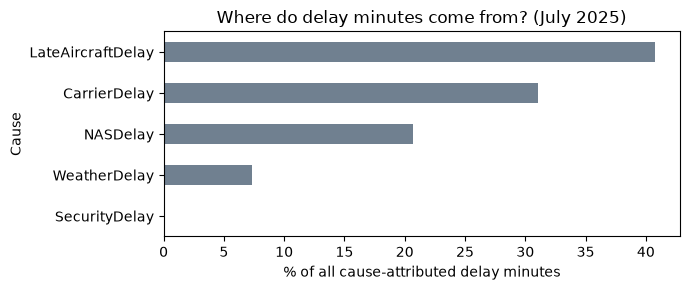

,minutes,% of total
CarrierDelay,4477900,31.1
WeatherDelay,1057529,7.3
NASDelay,2985238,20.7
SecurityDelay,15270,0.1
LateAircraftDelay,5880680,40.8


In [20]:
minutes = df[CAUSES].sum()
share = 100 * minutes / minutes.sum()

ax = share.sort_values().plot.barh(figsize=(7, 3), color="slategray")
ax.set_xlabel("% of all cause-attributed delay minutes")
ax.set_ylabel("Cause")
ax.set_title("Where do delay minutes come from? (July 2025)")
plt.tight_layout()
plt.show()
pd.DataFrame({"minutes": minutes.astype(int), "% of total": share.round(1)})

**Question:** What share of delay minutes is 'late aircraft'? What does it say about delay propagation, and why can none of these columns be a model input?

**My answer:** the most commun thing causing delay is the delay of a flight just before it , and none of the columns cannot be amodel input since they will be a leakge because they will help model find answer or something like this 

---
*End of batch 1. Batch 2 (UTC times, one tail through a day, ground-time distribution and chain-break threshold, consistency check, summary) comes next.*

## 7. From local clock times to UTC

**What:** find the time zone of every airport with `airportsdata`, and count the airports that have none.
**Why:** BTS times are **local clock times** at each airport. To put flights from different airports on one timeline
(and later to join weather and radar, which are in UTC), every time must first become UTC (Golden rule 1).

We use the time-zone **name** (e.g. `America/Phoenix`), never a fixed number of hours per zone: the name knows
the summer/winter rules of that place. Renamed airports go through `airport_aliases` from `config.yaml` first (`DJT` → `PBI`).

In [ ]:
# zoneinfo is in the standard library: it finds the time-zone rules by NAME.
from zoneinfo import ZoneInfo

import airportsdata
import numpy as np

# dict: "ATL" -> {"tz": "America/New_York", "lat": ..., "lon": ..., ...}
AIRPORTS = airportsdata.load("IATA")
# {"DJT": "PBI"}: code seen in BTS -> code known to airportsdata
ALIASES = cfg.get("airport_aliases") or {}


def tz_name(iata: str) -> str | None:
    """Time-zone NAME of an airport (e.g. 'America/Phoenix'); None if unknown to airportsdata."""
    info = AIRPORTS.get(ALIASES.get(iata, iata))      # alias first, then look the airport up
    return info["tz"] if info else None


# Every airport used in July. "|" between two sets = union (in one, in the other, or in both).
codes = sorted(set(df["Origin"]) | set(df["Dest"]))
no_tz = [c for c in codes if not tz_name(c)]
print(f"airports in the data: {len(codes)} | without a time zone: {len(no_tz)} {no_tz}")
pd.Series([tz_name(c) for c in codes if tz_name(c)]).value_counts().to_frame("airports")

**What:** the UTC offset of PHX, DEN and LAX in July and in January.
**Why:** Arizona (PHX) has **no daylight saving time**. Phoenix and Denver are both "Mountain time", but in summer
Denver moves its clocks and Phoenix does not. So in July Phoenix has the same clock as Los Angeles, and in January the same
clock as Denver. A table "Mountain time = UTC−7" would be wrong for one of them half of the year: this is why we use zone names.

In [ ]:
def utc_offset_hours(iata: str, day: str) -> float:
    """Local time minus UTC, in hours, at noon of that day (negative = behind UTC)."""
    noon = pd.Timestamp(f"{day} 12:00", tz=ZoneInfo(tz_name(iata)))
    return noon.utcoffset().total_seconds() / 3600


three = ["PHX", "DEN", "LAX"]
pd.DataFrame({
    "time zone": {a: tz_name(a) for a in three},
    "UTC offset on 2025-07-15": {a: utc_offset_hours(a, "2025-07-15") for a in three},
    "UTC offset on 2025-01-15": {a: utc_offset_hours(a, "2025-01-15") for a in three},
})

**What:** `to_utc(flight_date, hhmm_str, iata)`: one local clock time → one UTC timestamp, checked with `assert` on values we can compute by hand.
**Why:** a small function for **one** flight is easy to read and to test. `"2400"` means midnight at the **end** of the day, so it is `00:00` of the **next** day.

An `assert` does nothing when its condition is true and stops with an error when it is false: a tiny test.
(The real tests go in `tests/test_time.py`, step 1.5.)

In [ ]:
def to_utc(flight_date, hhmm_str: str, iata: str) -> pd.Timestamp:
    """Local clock time 'HHMM' at airport `iata` on `flight_date` -> UTC timestamp.

    '2400' is midnight at the END of the day, so it becomes 00:00 of the next day.
    """
    hhmm = str(hhmm_str).zfill(4)                    # "659" -> "0659" (safety)
    hours, minutes = int(hhmm[:2]), int(hhmm[2:])
    # Start at midnight of the flight date and ADD the hours and minutes.
    # Adding 24 hours lands on 00:00 of the next day, so "2400" needs no special case.
    midnight = pd.Timestamp(flight_date).normalize()
    local = midnight + pd.Timedelta(hours=hours, minutes=minutes)
    # 1) say "this clock time is in the airport's zone" (the zone picks summer or winter offset),
    # 2) convert to UTC.
    return local.tz_localize(ZoneInfo(tz_name(iata))).tz_convert("UTC")


# summer: Atlanta is UTC-4
assert to_utc("2025-07-15", "1430", "ATL") == pd.Timestamp("2025-07-15 18:30", tz="UTC")
# Arizona: UTC-7 all year
assert to_utc("2025-07-15", "1430", "PHX") == pd.Timestamp("2025-07-15 21:30", tz="UTC")
# winter: Atlanta is UTC-5
assert to_utc("2025-01-15", "1430", "ATL") == pd.Timestamp("2025-01-15 19:30", tz="UTC")
# "2400" = 00:00 of the next day
assert to_utc("2025-07-15", "2400", "ATL") == to_utc("2025-07-16", "0000", "ATL")
print("all 4 checks passed")
print("ATL 14:30 on 2025-07-15 ->", to_utc("2025-07-15", "1430", "ATL"))
print("PHX 14:30 on 2025-07-15 ->", to_utc("2025-07-15", "1430", "PHX"))
print("ATL 24:00 on 2025-07-15 ->", to_utc("2025-07-15", "2400", "ATL"))

**What:** the same conversion for the **whole table** → new column `sched_dep_utc`. Then `sched_arr_utc = sched_dep_utc + CRSElapsedTime` (minutes).

**Why a second function:** calling `to_utc` 631,428 times takes about 20 seconds. `to_utc_series` does the same steps on whole columns,
one time zone at a time (under a second). The next cell checks that both give the same result.

**Why not convert `CRSArrTime` directly?** Two traps:
1. **Overnight arrival:** BTS gives one date (`FlightDate` = the departure date) and an arrival *clock time*. A flight leaving at 23:00
   and landing at 01:10 arrives the **next day**, but nothing in `CRSArrTime` says so.
2. **Destination time zone:** `CRSArrTime` is on the *destination's* clock, which may be another zone than the departure.

`CRSElapsedTime` is a **duration** (scheduled minutes from gate to gate). A duration has no clock and no time zone:
departure UTC + duration = arrival UTC, always.

**Daylight-saving note:** twice a year one local hour does not exist (March) or exists twice (November). There, `to_utc` stops with an error
and `to_utc_series` returns a missing value (`NaT`): we never guess. July has no such hour; what to do with those few flights is a decision for the Silver step.

In [ ]:
def to_utc_series(dates: pd.Series, hhmm: pd.Series, iata: pd.Series) -> pd.Series:
    """Same as to_utc, for whole columns (same row index in and out)."""
    hhmm = hhmm.str.zfill(4)
    # Local time, no zone yet: midnight of the date + hours + minutes ("2400" -> next day 00:00).
    local = (dates
             + pd.to_timedelta(hhmm.str[:2].astype(int), unit="h")
             + pd.to_timedelta(hhmm.str[2:].astype(int), unit="m"))
    zone = iata.map(tz_name)                       # one zone name per row
    pieces = []
    for name, part in local.groupby(zone):         # all the rows of one zone together
        # "NaT" = missing value, not a guess, for the 2 special daylight-saving hours of a year
        in_zone = part.dt.tz_localize(ZoneInfo(name), ambiguous="NaT", nonexistent="NaT")
        pieces.append(in_zone.dt.tz_convert("UTC"))
    return pd.concat(pieces).reindex(dates.index)  # back to the original row order


df["sched_dep_utc"] = to_utc_series(df["FlightDate"], df["CRSDepTime"], df["Origin"])
# A duration has no time zone: departure (UTC) + scheduled minutes = arrival (UTC).
df["sched_arr_utc"] = df["sched_dep_utc"] + pd.to_timedelta(df["CRSElapsedTime"], unit="m")

print("missing sched_dep_utc:", df["sched_dep_utc"].isna().sum(),
      "| missing sched_arr_utc:", df["sched_arr_utc"].isna().sum())
df[["FlightDate", "Origin", "Dest", "CRSDepTime", "CRSArrTime", "CRSElapsedTime",
    "sched_dep_utc", "sched_arr_utc"]].head()

**What:** three checks of the new columns.
1. `to_utc` and `to_utc_series` agree on 2,000 random flights.
2. How many flights land "before" they leave **on the clock** (overnight flights, or short flights going west across a zone border)?
   Each of them would get a wrong arrival with the naive method `FlightDate + CRSArrTime`.
3. Cross-check: show `sched_arr_utc` on the **destination's** clock again; it should give back the BTS `CRSArrTime`.

**Why:** getting the same number in two independent ways is the best check of a time conversion.
The few flights that disagree in check 3 are rows where BTS's own `CRSElapsedTime` and `CRSArrTime` do not fit together (to note in the data-quality report).

In [ ]:
# 1. one-by-one function vs. column function (random_state=0 -> the same sample at every run)
sample = df.sample(2000, random_state=0)
# zip walks through the 3 columns together; strict=True = error if their lengths differ
rows = zip(sample["FlightDate"], sample["CRSDepTime"], sample["Origin"], strict=True)
one_by_one = pd.Series([to_utc(d, t, a) for d, t, a in rows], index=sample.index)
print("1. to_utc == to_utc_series on the sample:", (one_by_one == sample["sched_dep_utc"]).all())

# 2. arrival clock "before" departure clock (comparing text works: both are 4-digit 'HHMM')
arrives_before = df["CRSArrTime"] < df["CRSDepTime"]
print(f"2. flights with CRSArrTime < CRSDepTime on the clock: {arrives_before.sum():,}")

# 3. sched_arr_utc shown on the DESTINATION's clock should be CRSArrTime again
dest_zone = df["Dest"].map(tz_name)
back = pd.concat([part.dt.tz_convert(ZoneInfo(name)).dt.strftime("%H%M")
                  for name, part in df["sched_arr_utc"].groupby(dest_zone)]).reindex(df.index)
agree = back == df["CRSArrTime"]
print(f"3. arrival cross-check: {100 * agree.mean():.3f} % agree | {(~agree).sum()} disagree")
df.loc[~agree, ["FlightDate", "Reporting_Airline", "Origin", "Dest", "CRSDepTime", "CRSArrTime",
                "CRSElapsedTime"]].assign(arrival_from_elapsed=back[~agree]).head()

**Question:** Why is local time fine for the "delay by hour" chart (section 5) but wrong for joins (weather, radar, previous leg)? Give an example with two airports in different time zones.

**My answer:**

## 8. Follow one aircraft through a day

**What:** choose one aircraft (tail number) and one day with many legs.
**Why:** this is the core idea of the project, seen on real data: the same aircraft flies several legs, and a late arrival can make the next departure late.

How the example is chosen (written as code, so it is not a hidden hand-pick): at least 5 legs that day, none cancelled or diverted,
at least one departure from a hub, **first leg on time**, and then the day with the most legs marked "late aircraft".
It is chosen **because** it shows propagation clearly; most aircraft-days are calmer.

⚠️ `LateAircraftDelay` is used here only to choose and to look. It is never a model input.

In [ ]:
has_tail = tail.notna() & tail.ne("")       # `tail` (cleaned Tail_Number) comes from section 3

per_leg = df[has_tail].sort_values("sched_dep_utc").copy()
# True/False helper columns: summing them below counts the rows where the condition is true.
per_leg["from_a_hub"] = per_leg["Origin"].isin(HUBS)
per_leg["late_aircraft"] = per_leg["LateAircraftDelay"] > 0

# One row per (aircraft, day).
days = per_leg.groupby(["Tail_Number", "FlightDate"]).agg(
    legs=("Origin", "size"),
    cancelled=("Cancelled", "sum"),
    diverted=("Diverted", "sum"),
    hub_departures=("from_a_hub", "sum"),
    # rows are sorted by departure, so "first" = the first leg of the day
    first_dep_delay=("DepDelay", "first"),
    legs_late_aircraft=("late_aircraft", "sum"),
)
good = days[(days["legs"] >= 5) & (days["cancelled"] == 0) & (days["diverted"] == 0)
            & (days["hub_departures"] >= 1) & (days["first_dep_delay"] <= 0)]
good = good.sort_values(["legs_late_aircraft", "legs"], ascending=False)
print(f"aircraft-days in July: {len(days):,} | usable as an example: {len(good):,}")

# We take the first row. To follow another aircraft, replace the line below, for example by:
# TAIL, DAY = "N281NN", pd.Timestamp("2025-07-07")
TAIL, DAY = good.index[0]
print("chosen:", TAIL, "on", DAY.date())
good.head()

**What:** the legs of that aircraft sorted by **UTC** departure, with the scheduled ground time before each leg
(this leg's scheduled departure − the previous leg's scheduled arrival, both in UTC).
**Why:** the ground time is the **buffer**. If the aircraft lands 40 min late and the buffer is 80 min, the next leg can still leave on time;
with a 30 min buffer it cannot.

How to read it: compare the `ArrDelay` of one line with the `DepDelay` of the **next** line.
`CRSDepTime` / `CRSArrTime` are local clocks (origin / destination); the `_utc` columns are the same moments in UTC.

In [ ]:
one = df[(df["Tail_Number"] == TAIL) & (df["FlightDate"] == DAY)].copy()
one = one.sort_values("sched_dep_utc")
# shift(1) = "the value of the row above": here the previous leg's scheduled arrival
gap = one["sched_dep_utc"] - one["sched_arr_utc"].shift(1)
one["ground_before_min"] = gap.dt.total_seconds() / 60

show = one[["Origin", "Dest", "CRSDepTime", "CRSArrTime", "sched_dep_utc", "sched_arr_utc",
            "ground_before_min", "DepDelay", "ArrDelay", "LateAircraftDelay"]].copy()
for col in ["sched_dep_utc", "sched_arr_utc"]:
    # month-day hour:minute, shorter to read (still UTC)
    show[col] = show[col].dt.strftime("%m-%d %H:%M")
show.reset_index(drop=True)

**What:** the departure delay and the arrival delay of each leg, in flying order.
**Why:** a picture of the delay travelling with the aircraft. Under each leg: the scheduled ground time before it.
The dashed line is the 15-minute limit of our "delayed" label.

In [ ]:
route = one["Origin"] + "→" + one["Dest"]
# Text under each point: the route, and the ground time before that leg (none for the first).
labels = [f"{route.iloc[0]}\n(first leg)"]
for r, ground in zip(route.iloc[1:], one["ground_before_min"].iloc[1:], strict=True):
    labels.append(f"{r}\n({ground:.0f} min ground)")
x = range(len(one))

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(x, one["DepDelay"], marker="o", color="steelblue", label="Departure delay")
ax.plot(x, one["ArrDelay"], marker="s", color="darkorange", label="Arrival delay")
ax.axhline(15, color="gray", linestyle="--", linewidth=1, label="15 min = delayed")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Delay (minutes)")
ax.set_title(f"Aircraft {TAIL} on {DAY.date()}: delay leg by leg")
ax.legend()
plt.tight_layout()
plt.show()

**Question:** Does the delay accumulate during the day? Find one place where a long ground time (buffer) absorbs part of the delay, and one leg where the delay grows between departure and arrival (the aircraft lands much later than it left). What could explain the second case?

**My answer:**

## 9. Ground-time distribution: where does a chain end?

**What:** for **every** aircraft, sort **all** its July legs by UTC departure (across days, not day by day) and pair each leg with the one before it.
One pair = one **link**. For each link, `ground_h` = this leg's scheduled departure − the previous leg's scheduled arrival, in hours.
It is only computed when the aircraft is where it should be (this leg's origin = the previous leg's destination).

**Why:** a delay passes from one leg to the next only when the ground time is short; an overnight stop usually absorbs it.
We need one number that separates "same chain" from "new chain": `chain_break_ground_time_hours`. It is chosen **from the data**, not fixed at 12 h.

- Only **scheduled** times are used: they are known in advance, so building chains this way leaks nothing.
- Airports are compared with the BTS **airport ID** (stable), not the 3-letter code (it can be renamed, e.g. PBI → DJT in 2026).
- **Limit: July only.** The first July leg of each aircraft has no previous leg here (it was flown in June), and its last July leg has no next leg.
  So about one link per aircraft is missing, mostly long ones. The full pipeline will use all months together.

In [ ]:
# All legs that have a tail number, in flying order for each aircraft (whatever the day).
legs = df[has_tail].sort_values(["Tail_Number", "sched_dep_utc", "sched_arr_utc"])

# For each leg, fetch some values of the PREVIOUS leg of the same aircraft.
# groupby(...).shift(1) = "the row above, inside the same tail".
# The first leg of a tail has no row above: it gets a missing value.
PREV = {"DestAirportID": "prev_dest_id", "Dest": "prev_dest", "sched_arr_utc": "prev_arr_utc",
        "Cancelled": "prev_cancelled", "Diverted": "prev_diverted", "ArrDelay": "prev_arr_delay"}
previous = legs.groupby("Tail_Number")[list(PREV)].shift(1).rename(columns=PREV)
# Same rows as before, with the "prev_" columns added on the right.
legs = pd.concat([legs, previous], axis=1)

links = legs[legs["prev_arr_utc"].notna()].copy()      # a link needs a previous leg
links["same_airport"] = links["OriginAirportID"] == links["prev_dest_id"]
ground = (links["sched_dep_utc"] - links["prev_arr_utc"]).dt.total_seconds() / 3600
# A ground time has no meaning when the airports differ: keep it only for same-airport links.
links["ground_h"] = ground.where(links["same_airport"])

n_same = links["same_airport"].sum()
print(f"aircraft (tails): {legs['Tail_Number'].nunique():,} | legs: {len(legs):,} "
      f"| links: {len(links):,}")
print(f"links at the same airport: {n_same:,} ({100 * n_same / len(links):.1f} % of links)")

**What:** histogram of `ground_h` from 0 to 48 h (30-minute bins, **log scale** on the counts), and a zoom on the first 6 hours (10-minute bins, normal scale).
**Why:** we expect two groups: short turnarounds and overnight stops. The log scale is needed on the left because turnarounds are so many
that everything else would look flat. The threshold belongs in the emptiest zone between the two groups.

In [ ]:
g = links["ground_h"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(g[(g >= 0) & (g <= 48)], bins=np.arange(0, 48.5, 0.5), color="steelblue", log=True)
axes[0].set_title("Scheduled ground time between two legs, 0-48 h")
axes[0].set_xlabel("Ground time (hours, 30-min bins)")
axes[0].set_ylabel("Number of links (log scale)")
axes[0].set_xticks(range(0, 49, 4))

# Whole minutes, so that every value falls cleanly into one 10-minute bin.
minutes = (g[(g >= 0) & (g <= 6)] * 60).round()
axes[1].hist(minutes, bins=np.arange(0, 361, 10), color="darkorange")
axes[1].axvline(20, color="black", linestyle="--", linewidth=1,
                label="20 min (shorter = suspicious)")
axes[1].set_title("Zoom: the first 6 hours")
axes[1].set_xlabel("Ground time (minutes, 10-min bins)")
axes[1].set_ylabel("Number of links")
axes[1].set_xticks(range(0, 361, 30))
axes[1].legend()
plt.tight_layout()
plt.show()

**What:** percentiles of `ground_h`, and counts of impossible or suspicious values: **negative** (the next leg is scheduled to leave
before the previous one arrives = the two legs overlap), **under 20 minutes** (too short to turn an aircraft around), and over 48 h.
**Why:** negative and very short values are not real turnarounds. One reason seen in the data: BTS records the tail number of the aircraft that
**really flew**, but we order legs by **scheduled** times; after an aircraft swap or a very long delay, the scheduled order no longer matches what happened.
Such links must be broken (section 10), never used as "previous leg".

In [ ]:
MIN_GROUND_H = 20 / 60      # 20 minutes, written in hours

pct = g.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
pct.index = [f"p{q * 100:g}" for q in pct.index]

short = (g >= 0) & (g < MIN_GROUND_H)
print(f"links with a ground time: {len(g):,}")
print(f"  negative (overlap): {(g < 0).sum():,} ({100 * (g < 0).mean():.2f} %)")
print(f"  0 to 20 min:        {short.sum():,} ({100 * short.mean():.2f} %)")
print(f"  over 48 h:          {(g > 48).sum():,} ({100 * (g > 48).mean():.2f} %)")
pct.round(2).to_frame("ground time (hours)").T

**What:** find the emptiest 30-minute bin between the two groups (the "valley"), then print candidate thresholds around it with the share of links
each one would break (= links with a ground time above it). Then a wider table, from 2 h to 12 h.
**Why:** the valley is where the fewest links sit, so a threshold there has the fewest unclear cases on either side.
Around the valley the share barely changes from one candidate to the next: that is the sign of a real gap between two groups.

We look for the valley between 2 h and 8 h, i.e. between the two peaks seen on the left chart.

In [ ]:
counts, edges = np.histogram(g, bins=np.arange(0, 48.5, 0.5))    # the same 30-min bins as the chart
starts = edges[:-1]                                               # left edge of each bin
between = (starts >= 2) & (starts < 8)                            # the zone between the two peaks
# argmin = position of the smallest count -> the start of the bin with the fewest links
valley_h = float(starts[between][counts[between].argmin()])
print(f"emptiest 30-min bin between 2 h and 8 h: {valley_h:g} to {valley_h + 0.5:g} h "
      f"({counts[between].min():,} links)")

CANDIDATES_H = [valley_h - 1, valley_h, valley_h + 1]
print("\ncandidate threshold -> share of same-airport links it would break (ground time > it)")
for t in CANDIDATES_H:
    print(f"  {t:g} h -> {100 * (g > t).mean():.1f} %  ({(g > t).sum():,} links)")

wider = pd.Series({t: 100 * (g > t).mean() for t in [2, 3, 4, 5, 6, 8, 10, 12]})
wider.index.name = "threshold (h)"
wider.round(1).to_frame("% of links broken").T

In [ ]:
# The same histogram, 0-16 h, with the candidates drawn on it.
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(g[(g >= 0) & (g <= 16)], bins=np.arange(0, 16.5, 0.5), color="steelblue", log=True)
for t, style in zip(CANDIDATES_H, [":", "--", "-."], strict=True):   # one line style per candidate
    ax.axvline(t, color="black", linestyle=style, linewidth=1.5, label=f"candidate {t:g} h")
ax.set_title("Turnarounds (left) and overnight stops (right), with candidate thresholds")
ax.set_xlabel("Ground time (hours, 30-min bins)")
ax.set_ylabel("Number of links (log scale)")
ax.set_xticks(range(0, 17))
ax.legend()
plt.tight_layout()
plt.show()

**What (extra evidence, analysis only):** after a **late arrival** (previous leg ≥ 15 min late), how often does the next leg leave ≥ 15 min late,
depending on the ground time? Next to it: the same share for **all** links with that ground time (the normal level).
**Why:** the histogram shows where the two groups separate in the **schedule**. This chart shows where a delay **actually stops passing** to the next leg.
Where the two bars are close, a late arrival no longer changes anything: in practice the chain is over.

⚠️ This uses actual delays. It helps to choose the threshold; it is never a model input.

In [ ]:
# Links at the same airport where both legs were really flown.
flown_pair = (links["same_airport"] & links["prev_cancelled"].eq(0) & links["prev_diverted"].eq(0)
              & links["Cancelled"].eq(0))
pairs = links[flown_pair].copy()
pairs["prev_late"] = pairs["prev_arr_delay"] >= 15
pairs["next_late"] = pairs["DepDelay"] >= 15
# pd.cut sorts each ground time into a group: (0, 1] = more than 0 h and up to 1 h, and so on.
pairs["ground_group"] = pd.cut(pairs["ground_h"], [0, 1, 2, 3, 4, 5, 6, 8, 12, 24])

by_group = pairs.groupby("ground_group", observed=True)
after_late = pairs[pairs["prev_late"]].groupby("ground_group", observed=True)
by_ground = pd.DataFrame({
    "links": by_group.size(),
    "links after a late arrival": after_late.size(),
    "after a late arrival": 100 * after_late["next_late"].mean(),     # % of next legs leaving late
    "all links": 100 * by_group["next_late"].mean(),
})

ax = by_ground[["after a late arrival", "all links"]].plot.bar(
    figsize=(10, 4), color=["steelblue", "lightgray"], width=0.8, rot=0)
ax.set_xlabel("Scheduled ground time before the leg (hours)")
ax.set_ylabel("% of next legs leaving >= 15 min late")
ax.set_title("Does a late arrival still make the next leg late? (July 2025)")
plt.tight_layout()
plt.show()
by_ground.round(1)

### Decision: yours

The code above only prints **candidates**. **Ahmed chooses the final value and writes it in `config.yaml`** (`chain_break_ground_time_hours`),
with one sentence of justification in `docs/learning_log.md` and in the decisions log of `CLAUDE.md`.

Things to weigh:
- **Lower threshold:** chains keep only real turnarounds, but you cut links where a late arrival still matters
  (in the last chart: ground-time groups above your threshold where the blue bar is still clearly higher than the grey one).
- **Higher threshold:** you keep those links, but chains start to include long daytime waits and short nights, where the previous leg says little
  (groups where blue and grey are almost equal).
- This is **July only**. Check the histogram again when all months are loaded (winter schedules may differ).

**Question:** Where do the two groups separate on the charts? Which threshold do you choose, and why? What would go wrong with a much lower value (2 h) or a much higher one (12 h)?

**My answer:**

## 10. Broken links: how many, and why?

**What:** apply the broken-chain rules (CLAUDE.md §5) to every link and count the links each rule breaks.
A link can break several rules at once, so the lines do not add up to the total.
**Why:** Golden rule 5: no silent drops. A broken link means "this leg starts a new chain": it gets no previous-leg features and is not a propagation example.
We must know how many links are broken, and for which reason.

`THRESHOLD_H` below is a **trial value** from section 9. Change it to see the effect. It does **not** change `config.yaml`.

| Rule | Why the link is broken |
|---|---|
| Airport mismatch | The aircraft is not where the previous leg ended: a leg is missing (international, ferry flight) or the data is wrong |
| Previous leg cancelled | The aircraft did not fly it, so there is no delay to inherit |
| Previous leg diverted | The aircraft landed at another airport |
| Ground time > threshold | Overnight stop or maintenance: a new chain starts |
| Ground time < 20 min or overlap | Not a real turnaround (aircraft swap or data error) |
| This leg cancelled | It has no delay, so it can never be a label |
| Missing tail number | No chain at all (counted on flights, not on links) |

Not counted here: "impossible **actual** timing" (an aircraft swap visible only in the actual times). It needs actual departures and arrivals in UTC and comes with the Silver step.

In [ ]:
# >>> CHANGE ME <<<  Trial value: the middle candidate of section 9.
# To try another one, write a number instead, for example: THRESHOLD_H = 5.0
THRESHOLD_H = CANDIDATES_H[1]

# One True/False column per rule. Comparisons with a missing ground time (NaN) give False,
# so a link with an airport mismatch is counted by the first rule only.
rules = pd.DataFrame({
    "airport mismatch (Origin != previous Dest)": ~links["same_airport"],
    "previous leg cancelled": links["prev_cancelled"].eq(1),
    "previous leg diverted": links["prev_diverted"].eq(1),
    f"ground time > {THRESHOLD_H:g} h": links["ground_h"] > THRESHOLD_H,
    "ground time < 20 min or overlap (negative)": links["ground_h"] < MIN_GROUND_H,
    "this leg cancelled (no delay to predict)": links["Cancelled"].eq(1),
})
links["valid"] = ~rules.any(axis=1)        # valid = breaks no rule

table = rules.sum().to_frame("count")
table.loc["broken by at least one rule"] = (~links["valid"]).sum()
table.loc["VALID links"] = links["valid"].sum()
table["share (%)"] = (100 * table["count"] / len(links)).round(2)
table["share of"] = "links"
table.loc["missing tail number (no link possible)"] = [
    int((~has_tail).sum()), round(100 * (~has_tail).mean(), 2), "all flights"]

print(f"threshold tried: {THRESHOLD_H:g} h | links: {len(links):,} | flights: {len(df):,}")
table

**Question:** Which rule breaks the most links? Is that a data problem or normal airline life? Why does a cancelled previous leg break the chain even when the airports match?

**My answer:**

## 11. Consistency check (analysis only, never a model input)

**What:** on the valid links, compare two things that should agree:
- the airline says this leg was late because of a **late aircraft** (`LateAircraftDelay > 0`);
- our chain says the previous leg of that aircraft **arrived late** (`ArrDelay > 0`).

Two shares:
1. Of the legs with `LateAircraftDelay > 0`, how many have a late previous arrival in **our** chain? → **the real check: it should be high.**
2. Of the legs whose previous leg arrived late, how many have `LateAircraftDelay > 0`? → naturally lower: the buffer absorbs many small delays,
   and BTS fills the cause columns only when the leg itself **arrives** ≥ 15 min late.

**Why:** our chains use only tail numbers and scheduled times. The cause column is an independent statement by the airline.
**A low share 1 would mean the chain logic is wrong** (our "previous leg" would often be the wrong flight) and must be fixed before going on.
For comparison, the same shares on the **broken** links: there we expect a weaker agreement.

⚠️ `LateAircraftDelay` and `ArrDelay` are known only after the flight: they are used here to check, never as model inputs.

In [ ]:
def consistency(part: pd.DataFrame) -> pd.Series:
    """The two shares (in %) for a set of links."""
    late_aircraft = part["LateAircraftDelay"] > 0     # the airline's statement about THIS leg
    prev_late = part["prev_arr_delay"] > 0            # our chain: the previous leg arrived late
    # x[mask].mean() on True/False values = share of True among the rows kept by the mask
    share_1 = 100 * prev_late[late_aircraft].mean()
    share_2 = 100 * late_aircraft[prev_late].mean()
    # dtype=object keeps whole numbers as whole numbers in the display (no "439761.0")
    return pd.Series({
        "links": len(part),
        "legs with LateAircraftDelay > 0": int(late_aircraft.sum()),
        "1. of those, previous leg arrived late (%)": round(share_1, 1),
        "legs whose previous leg arrived late": int(prev_late.sum()),
        "2. of those, LateAircraftDelay > 0 (%)": round(share_2, 1),
    }, dtype=object)


pd.DataFrame({"valid links": consistency(links[links["valid"]]),
              "broken links": consistency(links[~links["valid"]])})

**Question:** Why is share 1 the real check, and why is share 2 expected to be lower? What could explain a leg with `LateAircraftDelay > 0` whose previous leg in our chain arrived on time?

**My answer:**

---
## Summary of batch 2

What this notebook now contains, to reuse in `src/transform/to_utc.py`, `src/features/rotation.py` and the tests:
- **UTC:** `to_utc` / `to_utc_series` convert local clock times with time-zone **names** (`2400` = next day 00:00; Phoenix has no daylight saving time).
  Scheduled arrival = scheduled departure (UTC) + `CRSElapsedTime`, which avoids both the overnight-arrival and the destination-time-zone traps.
- **One aircraft, one day:** delay travels from leg to leg; the scheduled ground time (buffer) decides how much of it is passed on.
- **Links:** every aircraft's legs sorted by scheduled UTC departure across days; scheduled ground time for each link; two groups (turnarounds, overnight stops) with a valley between them.
- **Broken links:** counted rule by rule, nothing dropped silently.
- **Consistency check:** the airline's "late aircraft" cause compared with our own chains.

**Still to do (Ahmed):**
1. Choose `chain_break_ground_time_hours`, write it in `config.yaml`, and note the reason (learning log + decisions log).
2. Put `THRESHOLD_H` to that value in section 10 and rerun sections 10–11.

**Limits to remember:** one month only (links across the June/August borders are missing); legs are ordered by **scheduled** time, so aircraft swaps show up
as overlaps or airport mismatches; the swap check on actual times and the daylight-saving hours are left for the Silver step.

### Check questions of step 1.2 (CLAUDE.md): answer without notes

**Question:** Why do delays grow later in the day? (Use what you saw in sections 5, 8 and 9.)

**My answer:**

**Question:** What share of delay minutes is "late aircraft"? (Section 6.) What does section 11 add to that number?

**My answer:**

---
*End of notebook 01.*